# Project 4: Fraud and Credit-Risk Classification

This notebook runs the supplied project across the two datasets and five classification frameworks.

Run the cells in order. If the Colab runtime disconnects, repeat the setup and upload steps.

## 1. Upload and extract the project

In [1]:
from google.colab import files
import os
import zipfile

uploaded = files.upload()
zip_name = next(name for name in uploaded if name.lower().endswith(".zip"))
PROJECT_DIR = "/content/fraud_project"

with zipfile.ZipFile(zip_name, "r") as archive:
    archive.extractall(PROJECT_DIR)

os.chdir(PROJECT_DIR)
print("Project folder:", os.getcwd())
print("Top-level files:", os.listdir("."))

Saving project4_code.zip to project4_code.zip
Project folder: /content/fraud_project
Top-level files: ['run_tabnet.py', 'common.py', 'figures', 'summarize.py', 'requirements.txt', 'data', 'Project4_Fraud_Classification.pptx', 'run_xgboost.py', 'README.md', 'results', '.gitignore', 'run_keras.py', 'VIVA_PREP.md', 'eda.py', 'run_flash.py', 'run_fastai.py', 'flash_compat.py']


## 2. Install libraries

In [2]:
%pip install -q xgboost tensorflow fastai pytorch-tabnet

In [3]:
import pandas as pd
import numpy as np
import sklearn
import xgboost
import tensorflow as tf
import torch
import fastai

print("Core imports successful")
print(
    "Python packages:",
    "pandas", pd.__version__,
    "| sklearn", sklearn.__version__,
    "| xgboost", xgboost.__version__,
    "| TensorFlow", tf.__version__,
    "| PyTorch", torch.__version__,
)

Core imports successful
Python packages: pandas 2.2.3 | sklearn 1.6.1 | xgboost 3.4.1 | TensorFlow 2.21.0 | PyTorch 2.14.1+cpu


## 3. Prepare the datasets

In [4]:
import os

os.makedirs("data", exist_ok=True)
!wget -q -O data/creditcard_sample.csv https://raw.githubusercontent.com/tiwvis/MLBD-Projects/main/data_sets/creditcard_sample.csv

print("Dataset files:", os.listdir("data"))

Dataset files: ['german.csv', 'creditcard_sample.csv']


In [5]:
credit = pd.read_csv("data/creditcard_sample.csv")
german = pd.read_csv("data/german.csv", header=None)

print("Credit-card sample shape:", credit.shape)
print("Credit-card columns:", credit.columns.tolist())
print("German Credit shape (raw, no header):", german.shape)
display(credit.head())
display(german.head())

Credit-card sample shape: (99999, 31)
Credit-card columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
German Credit shape (raw, no header): (1000, 21)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


## 4. Exploratory data analysis

In [6]:
!python eda.py

=== CREDIT CARD DATASET ===
shape: (99618, 31); missing values: 0; duplicate rows: 0
class counts: legit=99395, fraud=223 (0.224% fraud)
Amount by class:
         count    mean     std  min   25%    50%    75%       max
Class                                                            
0      99395.0   98.10  265.02  0.0  7.58  26.52  89.00  19656.53
1        223.0  116.17  256.03  0.0  1.00   8.00  99.99   1809.68
Top feature correlations with Class:
V17   -0.415
V14   -0.376
V3    -0.308
V12   -0.297
V10   -0.275
V16   -0.253
V7    -0.242
V11    0.186

=== GERMAN CREDIT DATASET ===
shape: (1000, 21); missing values: 0
class counts: good=700, bad=300 (30.0% bad)
numeric summary:
       duration   amount     age
count    1000.0   1000.0  1000.0
mean       20.9   3271.3    35.5
std        12.1   2822.7    11.4
min         4.0    250.0    19.0
25%        12.0   1365.5    27.0
50%        18.0   2319.5    33.0
75%        24.0   3972.2    42.0
max        72.0  18424.0    75.0
bad-credit rate

=== CREDIT CARD DATASET ===
shape: (99618, 31); missing values: 0; duplicate rows: 0
class counts: legit=99395, fraud=223 (0.224% fraud)
Amount by class:
         count    mean     std  min   25%    50%    75%       max
Class                                                            
0      99395.0   98.10  265.02  0.0  7.58  26.52  89.00  19656.53
1        223.0  116.17  256.03  0.0  1.00   8.00  99.99   1809.68
Top feature correlations with Class:
V17   -0.415
V14   -0.376
V3    -0.308
V12   -0.297
V10   -0.275
V16   -0.253
V7    -0.242
V11    0.186

=== GERMAN CREDIT DATASET ===
shape: (1000, 21); missing values: 0
class counts: good=700, bad=300 (30.0% bad)
numeric summary:
       duration   amount     age
count    1000.0   1000.0  1000.0
mean       20.9   3271.3    35.5
std        12.1   2822.7    11.4
min         4.0    250.0    19.0
25%        12.0   1365.5    27.0
50%        18.0   2319.5    33.0
75%        24.0   3972.2    42.0
max        72.0  18424.0    75.0
bad-credit rate

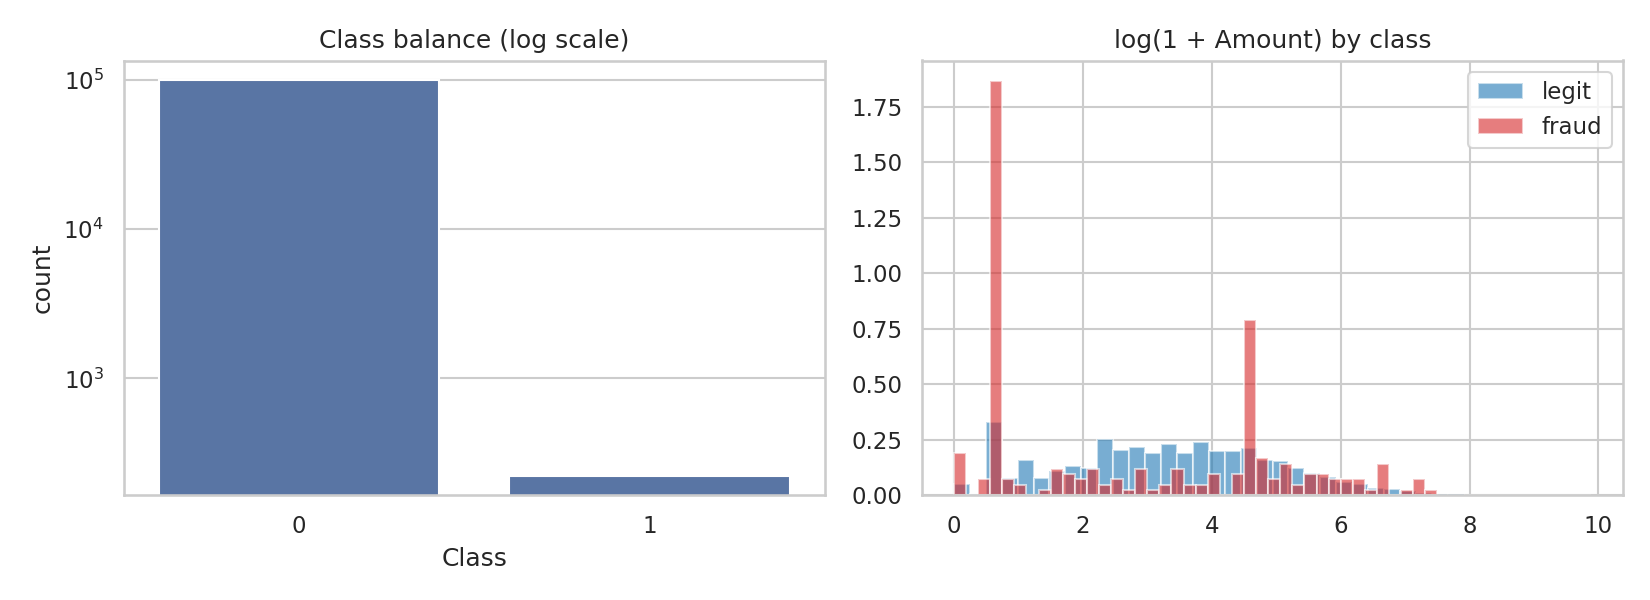

credit_corr_with_class.png


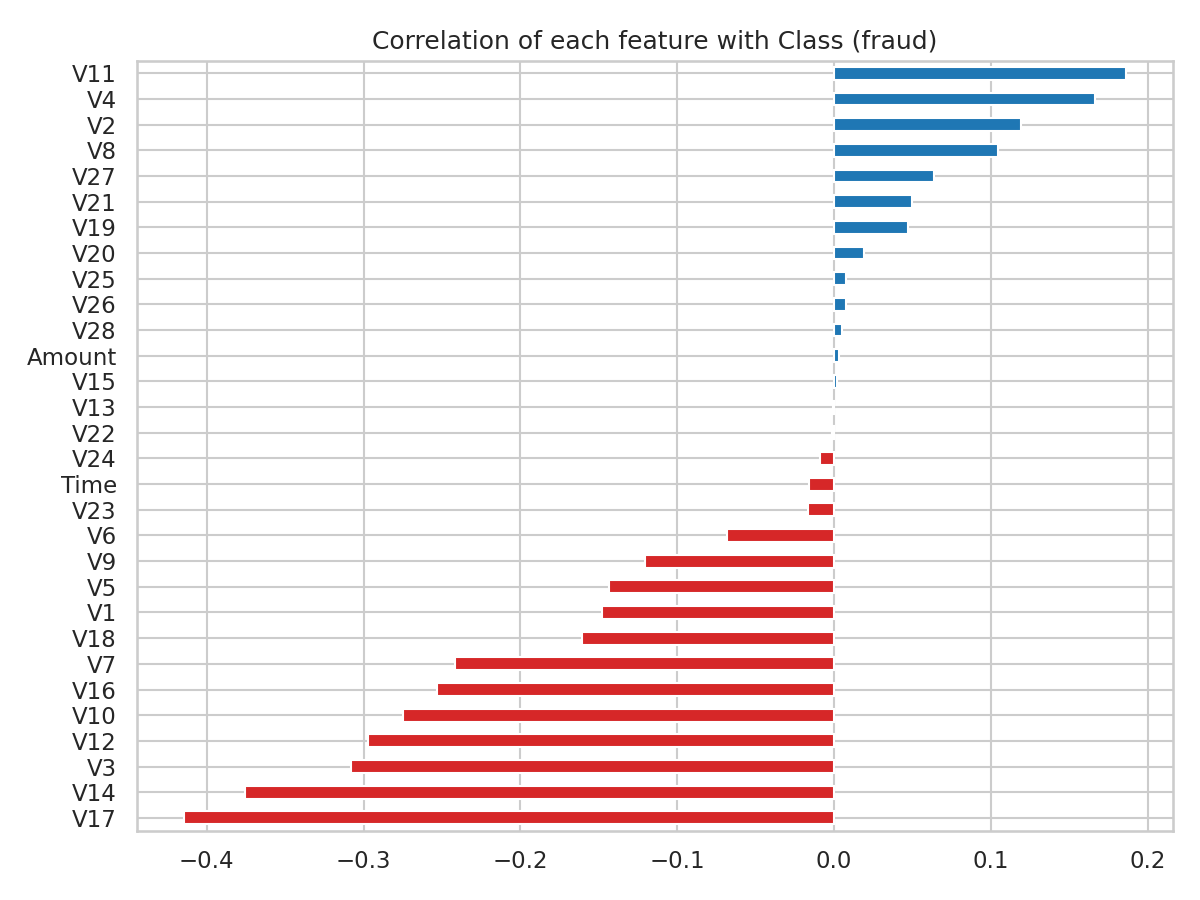

credit_top_features_boxplot.png


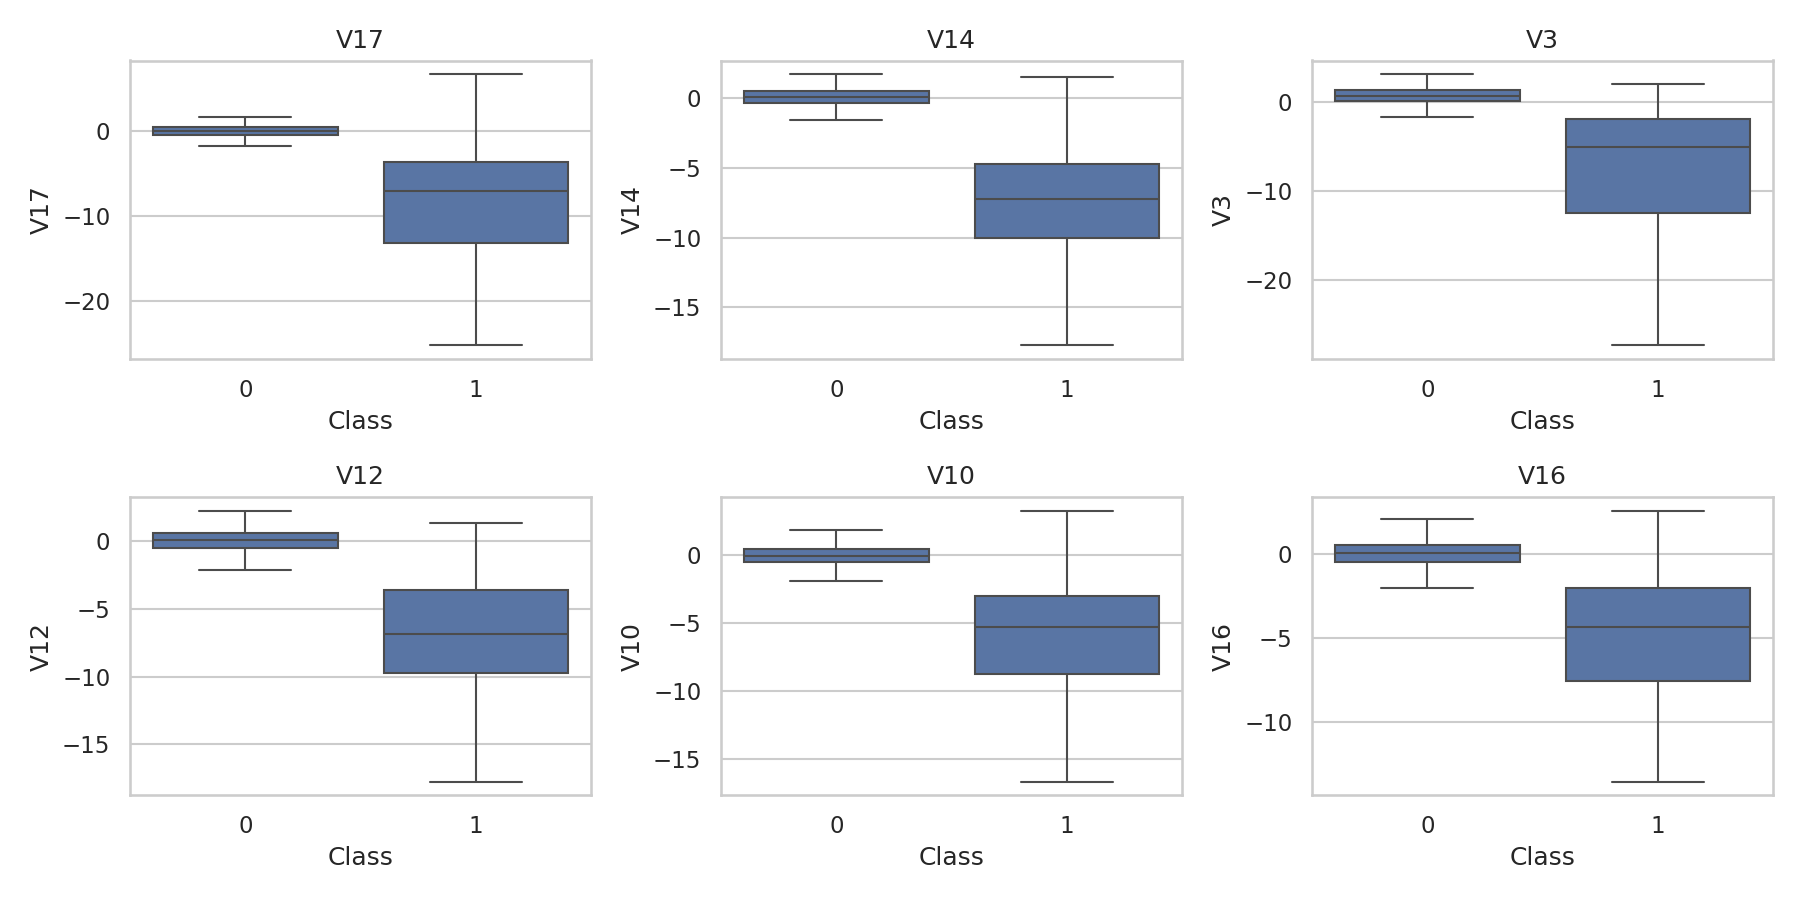

credit_fraud_by_hour.png


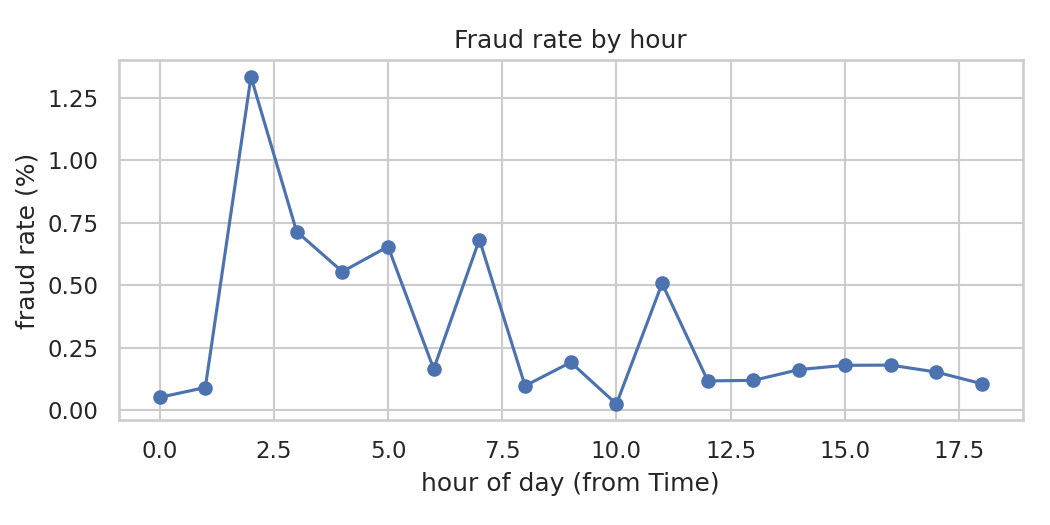

german_numeric_by_class.png


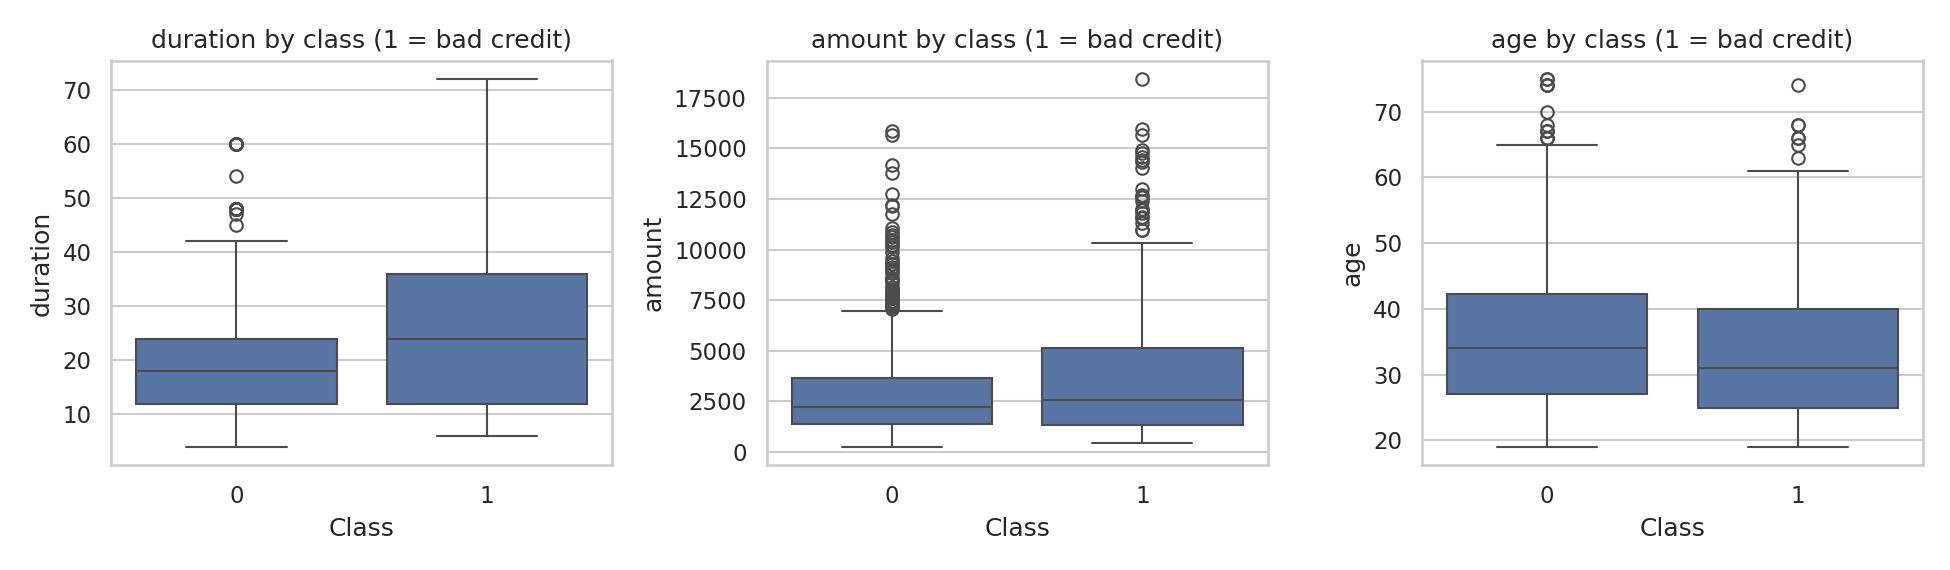

german_status_rate.png


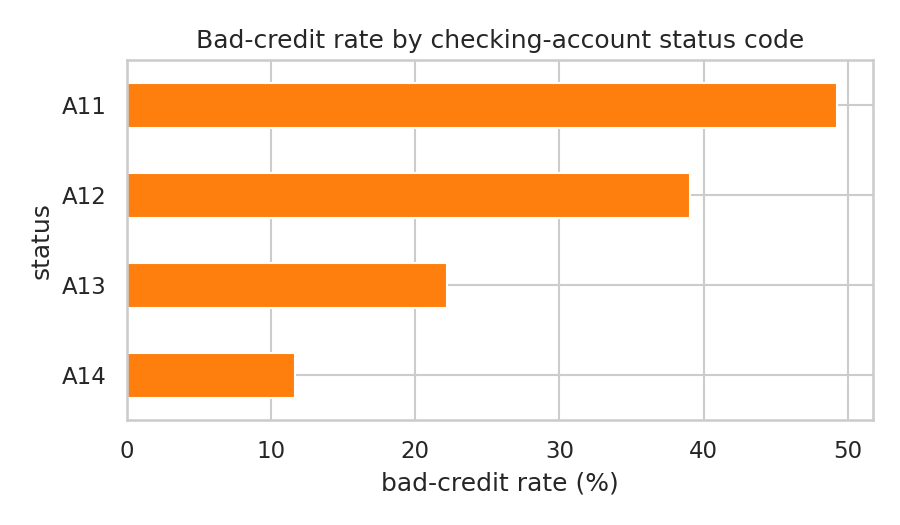

In [7]:
from IPython.display import display, Image

print(open("results/eda_summary.txt").read())

eda_figures = [
    "credit_class_amount.png",
    "credit_corr_with_class.png",
    "credit_top_features_boxplot.png",
    "credit_fraud_by_hour.png",
    "german_numeric_by_class.png",
    "german_status_rate.png",
]

for filename in eda_figures:
    print(filename)
    display(Image(filename=f"figures/{filename}"))

## 5. Train the classification models

Each training script accepts `credit` or `german`. The shared `common.py` module applies consistent preprocessing, stratified splitting, scaling, and metric calculations.

Run each framework and confirm that both dataset runs complete successfully.

In [8]:
!python run_xgboost.py credit
!python run_xgboost.py german

{
  "framework": "XGBoost",
  "dataset": "credit",
  "fit_seconds": 3.41,
  "lines_of_code": 9,
  "notes": "gradient-boosted trees; scale_pos_weight for imbalance",
  "accuracy": 0.9996,
  "precision": 1.0,
  "recall": 0.8222,
  "f1": 0.9024,
  "roc_auc": 0.9737,
  "pr_auc": 0.8923,
  "rmse": 0.0194,
  "mae": 0.0005,
  "r2": 0.8332
}
{
  "framework": "XGBoost",
  "dataset": "german",
  "fit_seconds": 0.12,
  "lines_of_code": 9,
  "notes": "gradient-boosted trees; scale_pos_weight for imbalance",
  "accuracy": 0.76,
  "precision": 0.5968,
  "recall": 0.6167,
  "f1": 0.6066,
  "roc_auc": 0.7865,
  "pr_auc": 0.6226,
  "rmse": 0.4225,
  "mae": 0.2956,
  "r2": 0.1498
}


In [9]:
!python run_keras.py credit
!python run_keras.py german

I0000 00:00:1794502193.275334    1412 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794502196.241604    1412 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
{
  "framework": "Keras",
  "dataset": "credit",
  "fit_seconds": 17.35,
  "lines_of_code": 12,
  "notes": "2 hidden layers (64, 32) + dropout; class-weighted loss; early stopping",
  "accuracy": 0.9988,
  "precision": 0.6842,
  "recall": 0.8667,
  "f1": 0.7647,
  "roc_auc": 0.9666,
  "pr_auc": 0.7801,
  "rmse": 0.0333,
  "mae": 0.0025,
  "r2": 0.5078
}
I0000 00:00:1794502220.214076    1801 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794502223.090490    1801 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
{
  "framework": "Keras",
  "dataset": "german",
  "fit_seconds": 4.55,
  "lines_of_code": 12,
  "notes": "2 hidden layers (64, 32) + dropout; class

In [10]:
!python run_fastai.py credit
!python run_fastai.py german

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
epoch     train_loss  valid_loss  accuracy  time    
0         0.082277    0.030467    0.998620  00:02     
1         0.039126    0.045622    0.993475  00:02     
2         0.035749    0.007471    0.999498  00:02     
3         0.018618    0.005928    0.999498  00:02     
4         0.014631    0.007041    0.999498  00:01     
5         0.011491    0.005640    0.999373  00:02     
6         0.010396    0.005082    0.999247  00:02     
7         0.015129    0.004081    0.999373  00:02     
{
  "framework": "fastai",
  "dataset": "credit",
  "fit_seconds": 18.29,
  "lines_of_code": 14,
  "notes": "fastai tabular_learner, layers [64, 32], one-cycle policy, weighted CE loss",
  "accuracy": 0.9991,
  "precision": 0.7647,
  "recall": 0.8667,
  "f1": 0.8125,
  "roc_auc": 0.9724,
  "pr_auc": 0.7781,
  "rmse": 0.0

In [11]:
!python run_tabnet.py credit
!python run_tabnet.py german


Early stopping occurred at epoch 8 with best_epoch = 2 and best_val_0_auc = 0.99972
/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
{
  "framework": "TabNet",
  "dataset": "credit",
  "fit_seconds": 39.47,
  "lines_of_code": 13,
  "notes": "TabNet (n_d=n_a=8, 3 steps), balanced sampler, early stopping on val AUC",
  "accuracy": 0.9812,
  "precision": 0.0956,
  "recall": 0.8667,
  "f1": 0.1722,
  "roc_auc": 0.9545,
  "pr_auc": 0.6737,
  "rmse": 0.1169,
  "mae": 0.0279,
  "r2": -5.0598
}
top TabNet features: [('V14', 0.299), ('V9', 0.206), ('V4', 0.195), ('V17', 0.047), ('V5', 0.043), ('V19', 0.036), ('Time', 0.034), ('V18', 0.028)]

Early stopping occurred at epoch 31 with best_epoch = 16 and best_val_0_auc = 0.76414
/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wr

### Lightning Flash (optional)

Lightning Flash 0.8.2 is an older, unmaintained dependency and may conflict with the current Colab environment. Run this section separately; continue only if installation and imports succeed.

In [16]:
import torch

print("PyTorch version:", torch.__version__)

try:
    import flash
    print("Lightning Flash imported successfully!")
except Exception as error:
    print("Lightning Flash import failed:")
    print(type(error).__name__, ":", error)

PyTorch version: 2.14.1+cpu
Lightning Flash import failed:
AttributeError : partially initialized module 'wandb' from '/usr/local/lib/python3.13/dist-packages/wandb/__init__.py' has no attribute 'errors' (most likely due to a circular import)


In [ ]:
%pip install --no-deps lightning-flash==0.8.2 pytorch-lightning==1.9.5 torchmetrics==0.10.3 pytorch-tabular==1.0.2
%pip install pytorch-forecasting omegaconf einops category_encoders rich scikit-base optuna

In [17]:
!python run_flash.py credit
!python run_flash.py german

/usr/local/lib/python3.13/dist-packages/flash/__init__.py:21: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(numpy, tp_name):
/usr/local/lib/python3.13/dist-packages/lightning_fabric/__init__.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
<sys>:0: FutureWarning: Please pass an instantiated object of the `InputTransform` class. Passing the Class and keyword arguments separately has been deprecated since v0.8.0 and will be removed in v0.9.0.
Using 'tabnet' provided by manujosephv/PyTorch Ta

## 6. Summarize results and compare models

In [18]:
!python summarize.py

      framework dataset  accuracy  precision  recall     f1  roc_auc  pr_auc   rmse    mae      r2  fit_seconds  lines_of_code
        XGBoost  credit    0.9996     1.0000  0.8222 0.9024   0.9737  0.8923 0.0194 0.0005  0.8332         3.41              9
          Keras  credit    0.9988     0.6842  0.8667 0.7647   0.9666  0.7801 0.0333 0.0025  0.5078        17.35             12
         fastai  credit    0.9991     0.7647  0.8667 0.8125   0.9724  0.7781 0.0305 0.0024  0.5873        18.29             14
         TabNet  credit    0.9812     0.0956  0.8667 0.1722   0.9545  0.6737 0.1169 0.0279 -5.0598        39.47             13
Lightning Flash  credit    0.9987     0.6863  0.7778 0.7292   0.9384  0.6779 0.0350 0.0051  0.4553        42.99             15
        XGBoost  german    0.7600     0.5968  0.6167 0.6066   0.7865  0.6226 0.4225 0.2956  0.1498         0.12              9
          Keras  german    0.6900     0.4886  0.7167 0.5811   0.7649  0.5662 0.4494 0.4038  0.0382         4.55

In [19]:
results = pd.read_csv("results/summary.csv")
display(results)

,framework,dataset,accuracy,precision,recall,f1,roc_auc,pr_auc,rmse,mae,r2,fit_seconds,lines_of_code
0,XGBoost,credit,0.9996,1.0000,0.8222,0.9024,0.9737,0.8923,0.0194,0.0005,0.8332,3.41,9
1,Keras,credit,0.9988,0.6842,0.8667,0.7647,0.9666,0.7801,0.0333,0.0025,0.5078,17.35,12
2,fastai,credit,0.9991,0.7647,0.8667,0.8125,0.9724,0.7781,0.0305,0.0024,0.5873,18.29,14
3,TabNet,credit,0.9812,0.0956,0.8667,0.1722,0.9545,0.6737,0.1169,0.0279,-5.0598,39.47,13
4,Lightning Flash,credit,0.9987,0.6863,0.7778,0.7292,0.9384,0.6779,0.0350,0.0051,0.4553,42.99,15
5,XGBoost,german,0.7600,0.5968,0.6167,0.6066,0.7865,0.6226,0.4225,0.2956,0.1498,0.12,9
6,Keras,german,0.6900,0.4886,0.7167,0.5811,0.7649,0.5662,0.4494,0.4038,0.0382,4.55,12
7,fastai,german,0.7000,0.5000,0.7167,0.5890,0.7530,0.5885,0.4490,0.3981,0.0401,0.17,14
8,TabNet,german,0.6200,0.4322,0.8500,0.5730,0.7416,0.5154,0.4744,0.4164,-0.0716,9.78,13
9,Lightning Flash,german,0.6450,0.4368,0.6333,0.5170,0.7040,0.5044,0.4818,0.3688,-0.1056,14.82,15


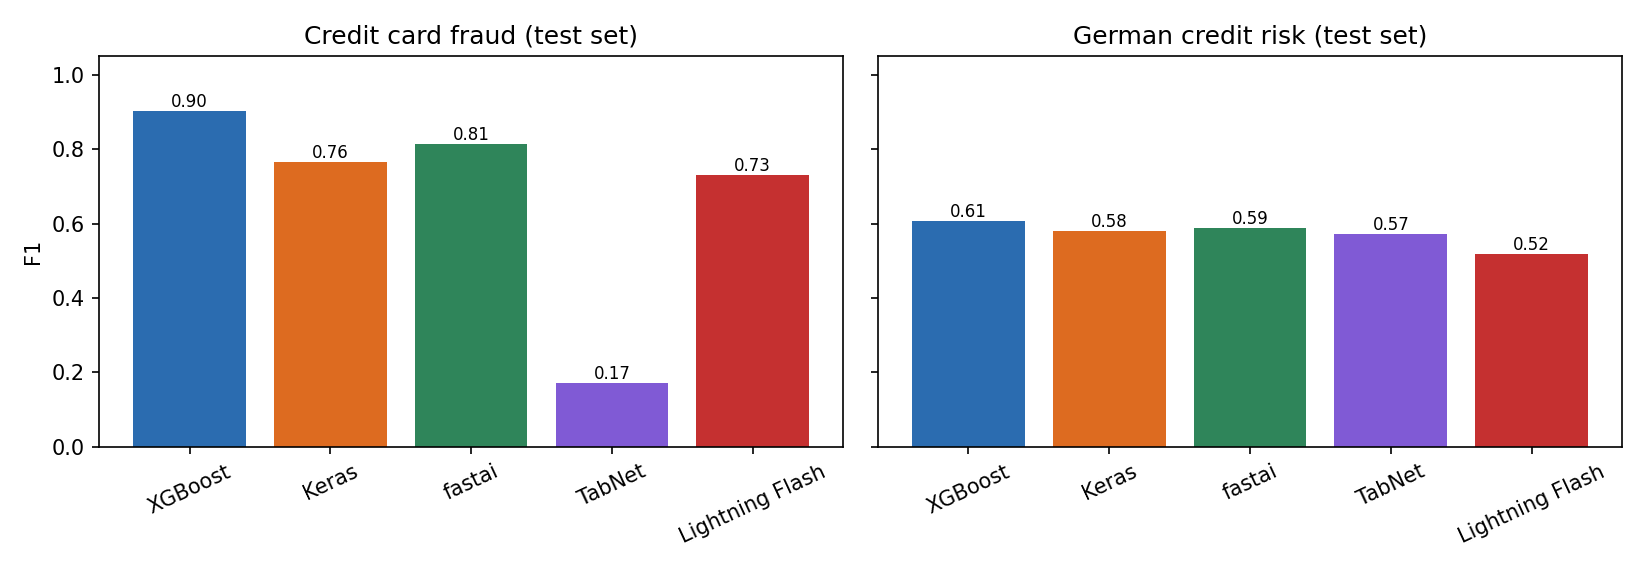

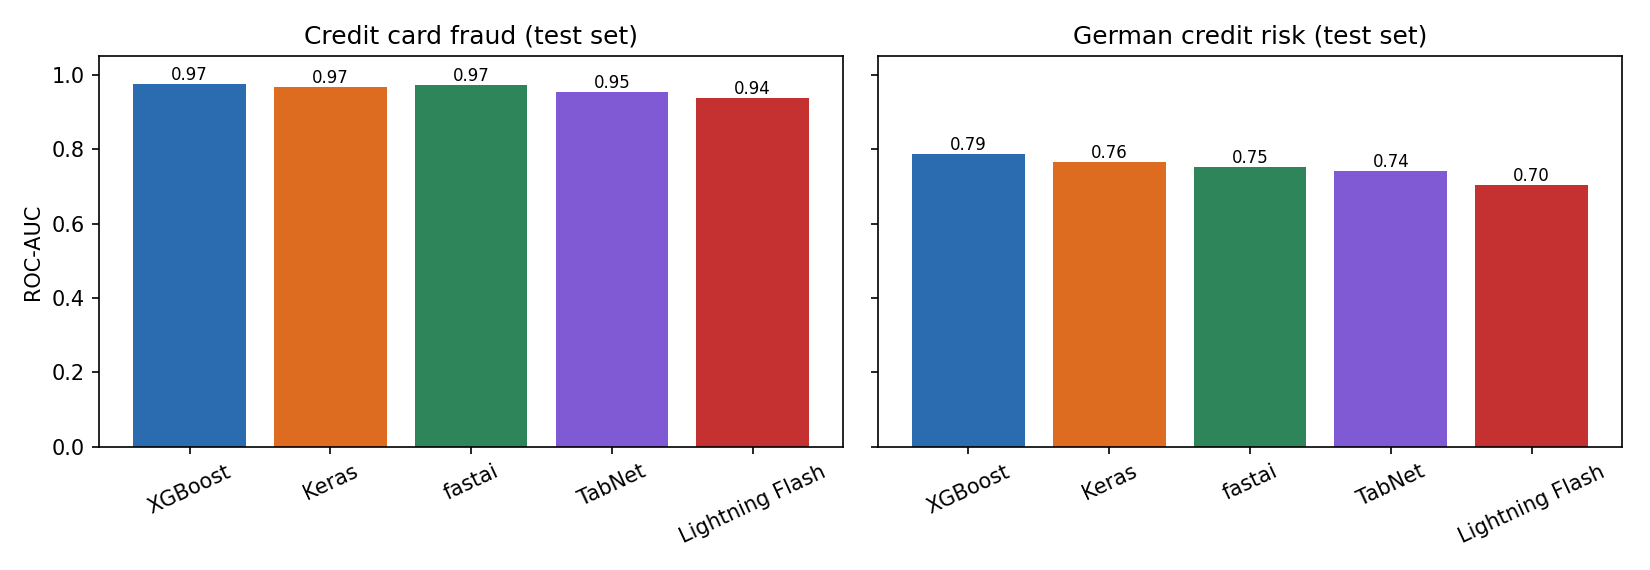

In [20]:
from IPython.display import display, Image
display(Image(filename="figures/compare_f1.png"))
display(Image(filename="figures/compare_auc.png"))

## 7. Verify generated results

Check that each framework produced result files for both datasets. Missing files indicate an incomplete run.

In [21]:
import glob
import os

result_files = sorted(glob.glob("results/*_*.json"))
print("\n".join(result_files))
print("Number of JSON result files:", len(result_files))

results/Keras_credit.json
results/Keras_german.json
results/Lightning Flash_credit.json
results/Lightning Flash_german.json
results/TabNet_credit.json
results/TabNet_german.json
results/XGBoost_credit.json
results/XGBoost_german.json
results/fastai_credit.json
results/fastai_german.json
Number of JSON result files: 10
